# Retail Data Infrastructure & Analytics Platform — Interactive Notebook

This notebook lets you **execute and inspect** the entire platform directly inside **VS Code**:
- Raw UCI dataset profile (`541,909` transactions) and Data Quality quarantine breakdown
- DuckDB dimensional Star Schema (`fact_sales`, `dim_customer`, `dim_product`, `dim_date`, `dim_country`)
- All **16 analytical SQL queries** executed live against `data/warehouse/retail_warehouse.duckdb`
- Visualizations for Monthly Revenue, Cancellation Impact, Top Products, and RFM Customer Segments

> **How to use in VS Code**: Click **Run All** at the top of the notebook (or press `Shift + Enter` on any cell) using the **Python 3.12** kernel.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Resolve project root whether notebook runs from root or notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "config" / "pipeline_config.yaml").exists() else Path.cwd().parent
WAREHOUSE_DB = PROJECT_ROOT / "data" / "warehouse" / "retail_warehouse.duckdb"
SQL_DIR = PROJECT_ROOT / "sql" / "analytics"
REPORTS_DIR = PROJECT_ROOT / "data" / "reports"

print(f"Project Root : {PROJECT_ROOT}")
print(f"Warehouse DB : {WAREHOUSE_DB} (exists={WAREHOUSE_DB.exists()})")

def run_sql_file(filename: str) -> pd.DataFrame:
    sql_text = (SQL_DIR / filename).read_text(encoding="utf-8")
    with duckdb.connect(str(WAREHOUSE_DB), read_only=True) as conn:
        return conn.sql(sql_text).df()

Project Root : c:\Users\rashm\Documents\AWS
Warehouse DB : c:\Users\rashm\Documents\AWS\data\warehouse\retail_warehouse.duckdb (exists=True)


## 1. Optional: Run the ETL Pipeline & Automated Tests from Notebook

Set `RUN_PIPELINE = True` or `RUN_TESTS = True` below if you want to trigger a fresh pipeline run or `pytest` directly from this notebook. By default they are `False` so the notebook renders all warehouse analytics in ~2 seconds.

In [2]:
RUN_PIPELINE = False   # Set True to re-run all 17 batches (--force)
RUN_TESTS = False      # Set True to run pytest inside the notebook

if RUN_PIPELINE:
    res = subprocess.run(
        [sys.executable, "scripts/run_pipeline.py", "--mode", "all", "--force"],
        cwd=PROJECT_ROOT,
        text=True,
    )
    assert res.returncode == 0, "Pipeline execution failed!"

if RUN_TESTS:
    res = subprocess.run(
        [sys.executable, "-m", "pytest"],
        cwd=PROJECT_ROOT,
        text=True,
    )
    assert res.returncode == 0, "Tests failed!"

print("Ready to inspect Data Quality, Warehouse Schema, and SQL Analytics.")

Ready to inspect Data Quality, Warehouse Schema, and SQL Analytics.


## 2. Raw Dataset Profile & Consolidated Data Quality Results

Inspects the verified JSON outputs generated by `scripts/inspect_dataset.py` and the validation stage (`src/validation/`).

In [3]:
raw_profile = json.loads((REPORTS_DIR / "raw_dataset_profile.json").read_text(encoding="utf-8"))
dq_report = json.loads((REPORTS_DIR / "consolidated_data_quality_report.json").read_text(encoding="utf-8"))

summary_df = pd.DataFrame(
    [
        {"Metric": "Total Raw Rows (UCI Online Retail)", "Value": f"{dq_report['total_rows_processed']:,}"},
        {"Metric": "Date Range", "Value": f"{raw_profile['date_range']['min']} -> {raw_profile['date_range']['max']}"},
        {"Metric": "Valid Rows Passed to Silver Zone", "Value": f"{dq_report['total_valid_rows']:,}"},
        {"Metric": "Quarantined Rows (Rejected Zone)", "Value": f"{dq_report['total_rejected_rows']:,}"},
        {"Metric": "Overall Data Quality Pass Rate", "Value": f"{dq_report['overall_pass_rate_pct']:.2f}%"},
        {"Metric": "Batches Processed", "Value": f"{dq_report['batch_count']}"},
    ]
)
display(summary_df)

rej_df = pd.DataFrame(
    [{"Rejection Code": k, "Rejected Rows": v} for k, v in dq_report["primary_rejection_totals"].items()]
)
print("Primary Rejection Breakdown:")
display(rej_df)

,Metric,Value
0,Total Raw Rows (UCI Online Retail),"541,909"
1,Date Range,2010-12-01 08:26:00 -> 2011-12-09 12:50:00
2,Valid Rows Passed to Silver Zone,"534,135"
3,Quarantined Rows (Rejected Zone),"7,774"
4,Overall Data Quality Pass Rate,98.57%
5,Batches Processed,17


Primary Rejection Breakdown:


,Rejection Code,Rejected Rows
0,DQ_EXACT_DUPLICATE,5256
1,DQ_NON_POSITIVE_UNIT_PRICE,2515
2,DQ_NON_STANDARD_INVOICE,3


## 3. DuckDB Star Schema Counts & Batch Lineage Audit

Checks row counts across `analytics.fact_sales` and all 4 dimension tables, then runs [`16_late_arriving_and_batch_audit.sql`](../sql/analytics/16_late_arriving_and_batch_audit.sql).

In [4]:
with duckdb.connect(str(WAREHOUSE_DB), read_only=True) as conn:
    table_counts = conn.sql(
        """
        SELECT 'analytics.fact_sales' AS table_name, COUNT(*) AS row_count FROM analytics.fact_sales
        UNION ALL SELECT 'analytics.dim_customer', COUNT(*) FROM analytics.dim_customer
        UNION ALL SELECT 'analytics.dim_product', COUNT(*) FROM analytics.dim_product
        UNION ALL SELECT 'analytics.dim_date', COUNT(*) FROM analytics.dim_date
        UNION ALL SELECT 'analytics.dim_country', COUNT(*) FROM analytics.dim_country
        UNION ALL SELECT 'analytics.etl_batch_audit', COUNT(*) FROM analytics.etl_batch_audit
        """
    ).df()
    totals = conn.sql(
        """
        SELECT
            COUNT(*) AS fact_rows,
            ROUND(SUM(gross_amount), 2) AS gross_revenue,
            ROUND(SUM(cancelled_amount), 2) AS cancelled_revenue,
            ROUND(SUM(net_amount), 2) AS net_revenue
        FROM analytics.fact_sales
        """
    ).df()

display(table_counts)
display(totals)
display(run_sql_file("16_late_arriving_and_batch_audit.sql"))

,table_name,row_count
0,analytics.fact_sales,534128
1,analytics.dim_customer,4372
2,analytics.dim_product,3827
3,analytics.dim_date,305
4,analytics.dim_country,38
5,analytics.etl_batch_audit,17


,fact_rows,gross_revenue,cancelled_revenue,net_revenue
0,534128,"10,631,048.74","893,979.73","9,737,069.01"


,batch_id,batch_type,is_late_arriving,rows_loaded,min_invoice_ts,max_invoice_ts,verified_fact_rows,batch_net_revenue,loaded_at
0,batch_0001_historical_backfill,backfill,True,485030,2010-12-01 08:26:00,2011-11-22 17:32:00,485023,"8,916,993.89",2026-11-12 20:42:16.371250
1,batch_0002_daily_2011-11-23,incremental,True,3550,2011-11-23 08:05:00,2011-11-23 17:45:00,3550,"78,223.52",2026-11-12 20:43:09.593844
2,batch_0003_daily_2011-11-24,incremental,True,3701,2011-11-24 08:28:00,2011-11-24 19:59:00,3701,"47,860.86",2026-11-12 20:43:14.355252
3,batch_0004_daily_2011-11-25,incremental,True,3062,2011-11-25 08:12:00,2011-11-25 17:31:00,3062,"50,310.39",2026-11-12 20:43:19.600587
4,batch_0005_daily_2011-11-27,incremental,True,2428,2011-11-27 10:34:00,2011-11-27 16:27:00,2428,"20,239.79",2026-11-12 20:43:24.214667
5,batch_0006_daily_2011-11-28,incremental,True,3275,2011-11-28 08:48:00,2011-11-28 17:09:00,3275,"55,242.56",2026-11-12 20:43:28.865997
6,batch_0007_daily_2011-11-29,incremental,True,4233,2011-11-29 08:07:00,2011-11-29 18:19:00,4233,"72,008.09",2026-11-12 20:43:33.539947
7,batch_0008_daily_2011-11-30,incremental,True,3417,2011-11-30 08:04:00,2011-11-30 17:42:00,3417,"59,049.59",2026-11-12 20:43:38.264468
8,batch_0009_daily_2011-12-01,incremental,True,2880,2011-12-01 08:12:00,2011-12-01 19:54:00,2880,"51,282.33",2026-11-12 20:43:42.867583
9,batch_0010_daily_2011-12-02,incremental,True,2825,2011-12-02 08:55:00,2011-12-02 17:13:00,2825,"56,898.47",2026-11-12 20:43:47.338524


## 4. Monthly Revenue Trend & Cancellation Impact

Executes [`01_monthly_revenue_trend.sql`](../sql/analytics/01_monthly_revenue_trend.sql) and [`07_cancellation_impact_on_revenue.sql`](../sql/analytics/07_cancellation_impact_on_revenue.sql).

,year_month,total_invoices,completed_orders,active_identified_customers,gross_revenue,cancelled_revenue,net_revenue,prev_month_net_revenue,mom_net_revenue_growth_pct
0,2010-12,1885,1559,948,"821,452.73","74,729.12","746,723.61",NaN,NaN
1,2011-01,1346,1086,783,"689,811.61","131,363.05","558,448.56","746,723.61",-25.21
2,2011-02,1319,1100,798,"522,545.56","25,519.15","497,026.41","558,448.56",-11.00
3,2011-03,1772,1454,1020,"716,215.26","34,201.28","682,013.98","497,026.41",37.22
4,2011-04,1486,1246,899,"536,968.49","44,600.65","492,367.84","682,013.98",-27.81
5,2011-05,1995,1681,1079,"769,296.61","47,202.51","722,094.10","492,367.84",46.66
6,2011-06,1862,1533,1051,"760,547.01","70,569.78","689,977.23","722,094.10",-4.45
7,2011-07,1745,1475,993,"718,076.12","37,919.13","680,156.99","689,977.23",-1.42
8,2011-08,1638,1360,980,"746,779.32","54,330.80","692,448.52","680,156.99",1.81
9,2011-09,2170,1837,1302,"1,056,435.19","38,838.51","1,017,596.68","692,448.52",46.96


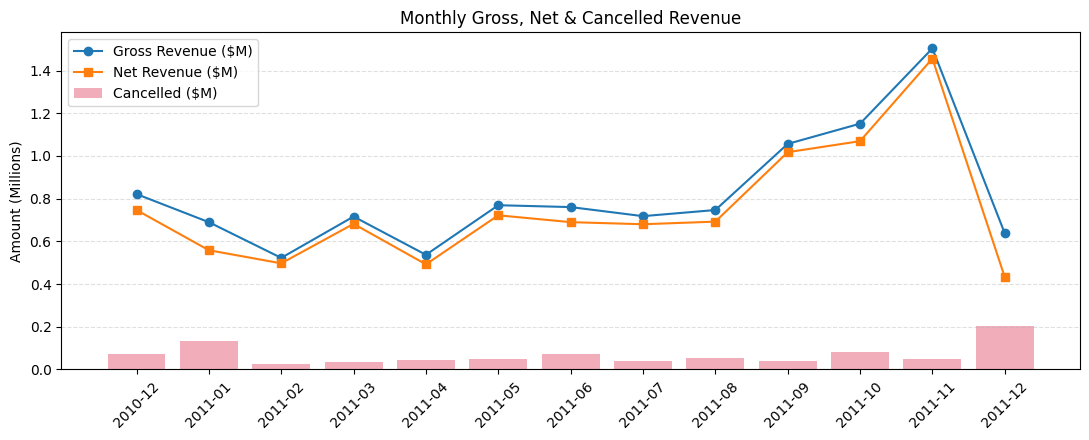

,year_month,positive_line_items,cancelled_line_items,gross_revenue,cancelled_revenue,net_revenue,cancellation_impact_pct,overall_avg_impact_pct
0,2010-12,"40,991.00",719.00,"821,452.73","74,729.12","746,723.61",9.10,9.25
1,2011-01,"34,060.00",700.00,"689,811.61","131,363.05","558,448.56",19.04,9.25
2,2011-02,"26,882.00",470.00,"522,545.56","25,519.15","497,026.41",4.88,9.25
3,2011-03,"35,497.00",696.00,"716,215.26","34,201.28","682,013.98",4.78,9.25
4,2011-04,"28,882.00",558.00,"536,968.49","44,600.65","492,367.84",8.31,9.25
5,2011-05,"35,917.00",621.00,"769,296.61","47,202.51","722,094.10",6.14,9.25
6,2011-06,"35,716.00",709.00,"760,547.01","70,569.78","689,977.23",9.28,9.25
7,2011-07,"38,395.00",684.00,"718,076.12","37,919.13","680,156.99",5.28,9.25
8,2011-08,"34,263.00",667.00,"746,779.32","54,330.80","692,448.52",7.28,9.25
9,2011-09,"48,900.00",801.00,"1,056,435.19","38,838.51","1,017,596.68",3.68,9.25


In [5]:
monthly_df = run_sql_file("01_monthly_revenue_trend.sql")
display(monthly_df)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly_df["year_month"], monthly_df["gross_revenue"] / 1e6, marker="o", label="Gross Revenue ($M)")
ax.plot(monthly_df["year_month"], monthly_df["net_revenue"] / 1e6, marker="s", label="Net Revenue ($M)")
ax.bar(monthly_df["year_month"], monthly_df["cancelled_revenue"] / 1e6, alpha=0.35, color="crimson", label="Cancelled ($M)")
ax.set_title("Monthly Gross, Net & Cancelled Revenue")
ax.set_ylabel("Amount (Millions)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

display(run_sql_file("07_cancellation_impact_on_revenue.sql"))

## 5. Top Products & Pareto 80/20 Concentration

Executes [`02_top_products_by_revenue.sql`](../sql/analytics/02_top_products_by_revenue.sql) and [`15_pareto_80_20_product_revenue.sql`](../sql/analytics/15_pareto_80_20_product_revenue.sql).

,revenue_rank,stock_code,product_description,units_sold,units_cancelled,order_count,gross_revenue,cancelled_revenue,net_revenue,pct_of_total_net_revenue
0,1,22423,REGENCY CAKESTAND 3 TIER,"13,851.00",855.00,1988,"174,156.54","9,697.05","164,459.49",1.68
1,2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"37,933.00","2,578.00",2265,"106,415.23","6,624.30","99,790.93",1.02
2,3,47566,PARTY BUNTING,"18,283.00",277.00,1685,"99,445.23","1,201.35","98,243.88",1.00
3,4,85099B,JUMBO BAG RED RETROSPOT,"48,371.00","1,115.00",2089,"94,159.81","1,984.02","92,175.79",0.94
4,5,23084,RABBIT NIGHT LIGHT,"30,739.00",108.00,994,"66,870.03",208.40,"66,661.63",0.68
5,6,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"19,329.00",453.00,1160,"64,875.59","1,160.35","63,715.24",0.65
6,7,84879,ASSORTED COLOUR BIRD ORNAMENT,"36,362.00",80.00,1455,"58,927.62",135.20,"58,792.42",0.60
7,8,79321,CHILLI LIGHTS,"10,302.00",80.00,661,"54,096.36",349.70,"53,746.66",0.55
8,9,22502,PICNIC BASKET WICKER SMALL,"1,937.00",75.00,463,"51,408.77",385.25,"51,023.52",0.52
9,10,22197,SMALL POPCORN HOLDER,"56,898.00",471.00,1392,"51,334.47",366.55,"50,967.92",0.52


,pareto_bucket,sku_count,pct_of_skus,bucket_revenue,pct_of_revenue
0,Top 80% Revenue Drivers,831,21.90,"7,821,774.70",79.98
1,Next 15% Long-Tail,965,25.43,"1,468,524.18",15.02
2,Bottom 5% Niche,1999,52.67,"489,005.63",5.00


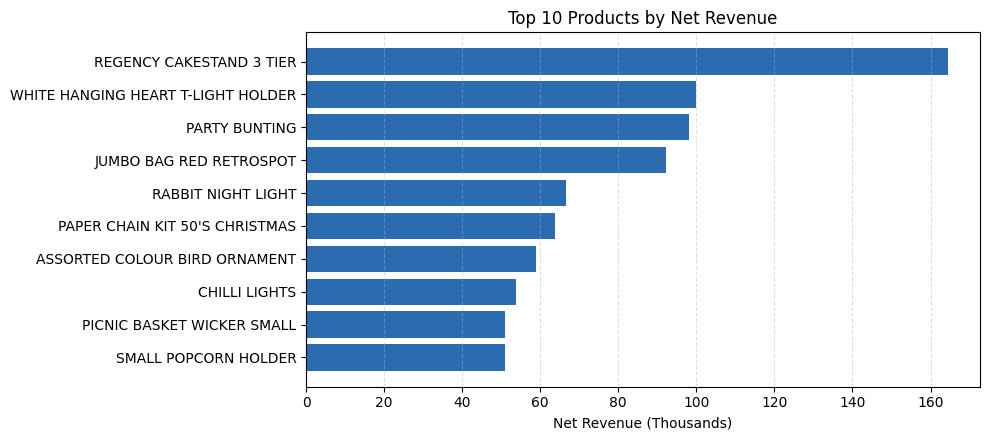

In [6]:
top_products = run_sql_file("02_top_products_by_revenue.sql")
display(top_products.head(10))

pareto_df = run_sql_file("15_pareto_80_20_product_revenue.sql")
display(pareto_df)

top10 = top_products.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(top10["product_description"].str.slice(0, 35), top10["net_revenue"] / 1e3, color="#2b6cb0")
ax.set_title("Top 10 Products by Net Revenue")
ax.set_xlabel("Net Revenue (Thousands)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 6. Country Revenue Share & Cancellation Rates

Executes [`03_country_revenue_share.sql`](../sql/analytics/03_country_revenue_share.sql) and [`06_cancellation_rate_by_country.sql`](../sql/analytics/06_cancellation_rate_by_country.sql).

In [7]:
country_df = run_sql_file("03_country_revenue_share.sql")
display(country_df.head(12))

cancel_country = run_sql_file("06_cancellation_rate_by_country.sql")
display(cancel_country)

,country_rank,country_name,region_group,total_invoices,unique_customers,gross_revenue,cancelled_revenue,net_revenue,revenue_share_pct,cumulative_revenue_share_pct
0,1,United Kingdom,United Kingdom,21390,3949,"8,990,682.03","812,491.79","8,178,190.24",83.99,83.99
1,2,Netherlands,Europe,100,9,"285,446.34",784.80,"284,661.54",2.92,86.91
2,3,EIRE,Europe,360,3,"283,140.52","20,147.14","262,993.38",2.70,89.61
3,4,Germany,Europe,603,95,"228,678.40","7,168.93","221,509.47",2.27,91.89
4,5,France,Europe,461,87,"209,625.37","12,308.26","197,317.11",2.03,93.92
5,6,Australia,Asia-Pacific,69,9,"138,453.81","1,444.04","137,009.77",1.41,95.32
6,7,Switzerland,Europe,74,21,"57,067.60",704.55,"56,363.05",0.58,95.90
7,8,Spain,Europe,105,31,"61,558.56","6,802.53","54,756.03",0.56,96.46
8,9,Belgium,Europe,119,25,"41,196.34",285.38,"40,910.96",0.42,96.88
9,10,Sweden,Europe,46,8,"38,367.83","1,782.42","36,585.41",0.38,97.26


,country_name,total_invoices,cancelled_invoices,invoice_cancellation_rate_pct,gross_revenue,cancelled_revenue,revenue_cancellation_rate_pct,net_revenue
0,Portugal,71,13,18.31,"33,683.05","4,380.08",13.00,"29,302.97"
1,Spain,105,15,14.29,"61,558.56","6,802.53",11.05,"54,756.03"
2,United Kingdom,21390,3372,15.76,"8,990,682.03","812,491.79",9.04,"8,178,190.24"
3,EIRE,360,72,20.00,"283,140.52","20,147.14",7.12,"262,993.38"
4,France,461,69,14.97,"209,625.37","12,308.26",5.87,"197,317.11"
5,Italy,55,17,30.91,"17,483.24",592.73,3.39,"16,890.51"
6,Germany,603,146,24.21,"228,678.40","7,168.93",3.13,"221,509.47"
7,Switzerland,74,20,27.03,"57,067.60",704.55,1.23,"56,363.05"
8,Australia,69,12,17.39,"138,453.81","1,444.04",1.04,"137,009.77"
9,Belgium,119,21,17.65,"41,196.34",285.38,0.69,"40,910.96"


## 7. Customer Analytics: RFM Segmentation, Top CLV, Loyalty & Cohort Retention

Executes [`04_customer_rfm_segmentation.sql`](../sql/analytics/04_customer_rfm_segmentation.sql), [`05_customer_lifetime_value_ranking.sql`](../sql/analytics/05_customer_lifetime_value_ranking.sql), [`13_repeat_vs_one_time_customers.sql`](../sql/analytics/13_repeat_vs_one_time_customers.sql), and [`08_cohort_retention_analysis.sql`](../sql/analytics/08_cohort_retention_analysis.sql).

,rfm_segment,customer_count,avg_recency_days,avg_frequency_orders,avg_monetary_spend,total_segment_revenue
0,Champions,479,5.80,15.57,"8,880.74","4,253,872.29"
1,Loyal Customers,1105,20.60,5.08,"1,951.96","2,156,912.80"
2,At Risk,743,83.30,3.40,"1,229.18","913,284.29"
3,Hibernating / Needs Attention,1415,203.00,1.49,496.22,"702,156.29"
4,Recent / Promising,575,23.30,1.39,461.78,"265,522.89"


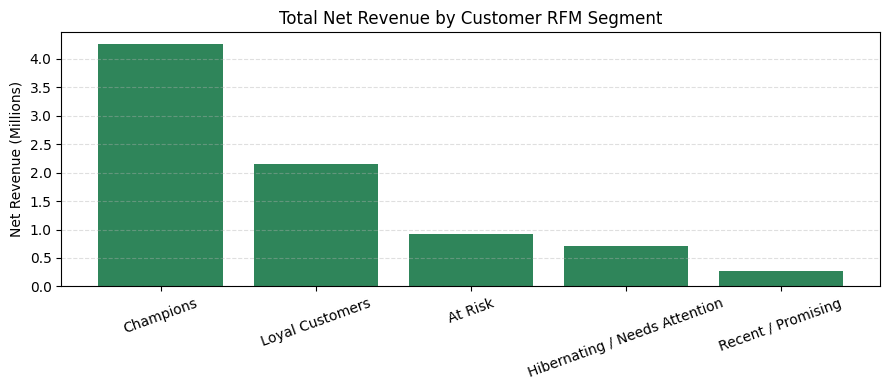

Top 10 Customers by Lifetime Value:


,global_clv_rank,country_clv_rank,customer_id,primary_country,active_span_days,completed_orders,cancelled_orders,gross_spend,cancelled_spend,net_lifetime_value,avg_order_value
0,1,1,14646,Netherlands,354,73,3,"280,206.02",717.00,"279,489.02","3,828.62"
1,2,1,18102,United Kingdom,368,60,2,"259,657.30","3,218.81","256,438.49","4,273.97"
2,3,2,17450,United Kingdom,360,46,9,"194,390.79","7,068.62","187,322.17","4,072.22"
3,4,1,14911,EIRE,373,201,47,"143,711.17","11,252.44","132,458.73",659.00
4,5,1,12415,Australia,314,21,5,"124,914.53","1,189.08","123,725.45","5,891.69"
5,6,2,14156,EIRE,364,55,11,"117,210.08","3,995.49","113,214.59","2,058.45"
6,7,3,17511,United Kingdom,372,31,15,"91,062.38","2,937.00","88,125.38","2,842.75"
7,8,4,16684,United Kingdom,355,28,3,"66,653.56",761.48,"65,892.08","2,353.29"
8,9,5,13694,United Kingdom,371,50,10,"65,039.62","2,349.08","62,690.54","1,253.81"
9,10,6,15311,United Kingdom,374,91,27,"60,632.75","1,348.56","59,284.19",651.47


Customer Loyalty Tiers:


,loyalty_tier,customer_count,pct_of_customers,total_orders,total_revenue,pct_of_revenue,avg_customer_spend
0,1_One-Time (1 order),1493,34.42,"1,493.00","613,989.56",6.91,411.25
1,2_Repeat (2-4 orders),1731,39.90,"4,746.00","1,940,750.02",21.84,"1,121.17"
2,3_Frequent (5-10 orders),777,17.91,"5,179.00","1,948,503.30",21.92,"2,507.73"
3,4_VIP (11+ orders),337,7.77,"7,114.00","4,383,966.01",49.33,"13,008.80"


Monthly Cohort Retention Matrix (%):


months_since_first_purchase,0,1,2,3,4,5,6
cohort_month,,,,,,,
2010-12,100.00,36.61,32.32,38.42,36.27,39.77,36.27
2011-01,100.00,22.06,26.62,23.02,32.13,28.78,24.70
2011-02,100.00,18.68,18.68,28.42,27.11,24.74,25.26
2011-03,100.00,15.04,25.22,19.91,22.35,16.81,26.77
2011-04,100.00,21.33,20.33,21.00,19.67,22.67,21.67
2011-05,100.00,19.01,17.25,17.25,20.77,23.24,26.41
2011-06,100.00,17.36,15.70,26.45,23.14,33.47,9.50
2011-07,100.00,18.09,20.74,22.34,27.13,11.17,NaN
2011-08,100.00,20.71,24.85,24.26,12.43,NaN,NaN


In [8]:
rfm_df = run_sql_file("04_customer_rfm_segmentation.sql")
display(rfm_df)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(rfm_df["rfm_segment"], rfm_df["total_segment_revenue"] / 1e6, color="#2f855a")
ax.set_title("Total Net Revenue by Customer RFM Segment")
ax.set_ylabel("Net Revenue (Millions)")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Top 10 Customers by Lifetime Value:")
display(run_sql_file("05_customer_lifetime_value_ranking.sql").head(10))

print("Customer Loyalty Tiers:")
display(run_sql_file("13_repeat_vs_one_time_customers.sql"))

cohort_raw = run_sql_file("08_cohort_retention_analysis.sql")
cohort_pivot = cohort_raw.pivot(
    index="cohort_month", columns="months_since_first_purchase", values="retention_rate_pct"
)
print("Monthly Cohort Retention Matrix (%):")
display(cohort_pivot)

## 8. Operational Cadence & Complete 16-Query Verification

Displays Basket/AOV distribution (`12`), Day-of-Week (`11`), Hourly Heatmap (`10`), Daily Rolling 7-Day sample (`09`), Top-5 Product MoM (`14`), and verifies all 16 SQL scripts in `sql/analytics/`.

In [9]:
print("Basket Size & AOV Distribution (Identified vs Guest):")
display(run_sql_file("12_basket_size_and_aov_distribution.sql"))

print("Day-of-Week Performance:")
display(run_sql_file("11_day_of_week_performance.sql"))

print("Hourly Shopping Activity (Peak Hours):")
display(run_sql_file("10_hourly_shopping_heatmap.sql").sort_values("net_revenue", ascending=False).head(8))

print("Daily Rolling 7-Day Revenue (Latest 10 Active Days):")
display(run_sql_file("09_daily_rolling_7d_revenue.sql").tail(10))

print("Top 5 Products Monthly MoM Trend (Sample):")
display(run_sql_file("14_product_monthly_mom_growth.sql").head(10))

# Verify every SQL file in sql/analytics/
audit_rows = []
for sql_file in sorted(SQL_DIR.glob("*.sql")):
    df_out = run_sql_file(sql_file.name)
    audit_rows.append({"query_file": sql_file.name, "rows_returned": len(df_out), "columns": len(df_out.columns)})

display(pd.DataFrame(audit_rows))

Basket Size & AOV Distribution (Identified vs Guest):


,customer_type,total_orders,avg_lines_per_basket,avg_units_per_basket,mean_aov,median_aov,p90_aov,total_gross_sales
0,Identified Customer,18532,21.19,278.01,479.56,302.57,820.77,"8,887,208.89"
1,Guest / Unidentified,1427,92.63,294.62,"1,222.03",464.92,"3,058.92","1,743,839.85"


Day-of-Week Performance:


,day_of_week,day_name,is_weekend,active_calendar_days,completed_orders,total_net_revenue,avg_daily_revenue,avg_order_value
0,1,Monday,False,47,3126,"1,584,895.30","33,721.18",507.00
1,2,Tuesday,False,52,3554,"1,965,703.61","37,801.99",553.10
2,3,Wednesday,False,53,3690,"1,730,088.43","32,643.18",468.86
3,4,Thursday,False,53,4246,"2,108,701.53","39,786.82",496.63
4,5,Friday,False,50,3139,"1,549,020.68","30,980.41",493.48
5,7,Sunday,True,50,2204,"798,659.46","15,973.19",362.37


Hourly Shopping Activity (Peak Hours):


,invoice_hour,completed_orders,units_sold,net_revenue,share_of_revenue_pct,hour_revenue_rank
6,12,3220,"836,642.00","1,357,595.12",13.94,1
4,10,2361,"812,678.00","1,327,329.89",13.63,2
9,15,2336,"626,989.00","1,186,819.41",12.19,3
7,13,2753,"703,750.00","1,172,985.87",12.05,4
5,11,2396,"671,281.00","1,146,457.49",11.77,5
8,14,2456,"597,055.00","1,102,470.80",11.32,6
3,9,1484,"517,985.00","766,524.17",7.87,7
10,16,1335,"330,609.00","727,666.67",7.47,8


Daily Rolling 7-Day Revenue (Latest 10 Active Days):


,full_date,day_name,completed_orders,daily_net_revenue,rolling_7d_avg_revenue,cumulative_ytd_revenue
295,2011-11-29,Tuesday,135,"72,008.09","55,138.03","8,498,594.75"
296,2011-11-30,Wednesday,108,"59,049.59","54,704.97","8,557,644.34"
297,2011-12-01,Thursday,121,"51,282.33","50,856.23","8,608,926.67"
298,2011-12-02,Friday,120,"56,898.47","52,147.32","8,665,825.14"
299,2011-12-04,Sunday,66,"24,421.82","48,448.95","8,690,246.96"
300,2011-12-05,Monday,127,"57,630.20","53,790.44","8,747,877.16"
301,2011-12-06,Tuesday,115,"54,109.39","53,628.56","8,801,986.55"
302,2011-12-07,Wednesday,106,"74,952.61","54,049.20","8,876,939.16"
303,2011-12-08,Thursday,120,"81,294.33","57,227.02","8,958,233.49"
304,2011-12-09,Friday,44,"32,111.91","54,488.39","8,990,345.40"


Top 5 Products Monthly MoM Trend (Sample):


,stock_code,product_description,year_month,monthly_net_revenue,prev_month_revenue,mom_growth_pct
0,22423,REGENCY CAKESTAND 3 TIER,2010-12,"26,722.16",NaN,NaN
1,22423,REGENCY CAKESTAND 3 TIER,2011-01,"11,742.50","26,722.16",-56.06
2,22423,REGENCY CAKESTAND 3 TIER,2011-02,"10,491.54","11,742.50",-10.65
3,22423,REGENCY CAKESTAND 3 TIER,2011-03,"16,817.85","10,491.54",60.30
4,22423,REGENCY CAKESTAND 3 TIER,2011-04,"14,280.90","16,817.85",-15.08
5,22423,REGENCY CAKESTAND 3 TIER,2011-05,"12,217.27","14,280.90",-14.45
6,22423,REGENCY CAKESTAND 3 TIER,2011-06,"9,453.64","12,217.27",-22.62
7,22423,REGENCY CAKESTAND 3 TIER,2011-07,"13,726.56","9,453.64",45.20
8,22423,REGENCY CAKESTAND 3 TIER,2011-08,"8,393.55","13,726.56",-38.85
9,22423,REGENCY CAKESTAND 3 TIER,2011-09,"9,315.03","8,393.55",10.98


,query_file,rows_returned,columns
0,01_monthly_revenue_trend.sql,13,9
1,02_top_products_by_revenue.sql,20,10
2,03_country_revenue_share.sql,38,10
3,04_customer_rfm_segmentation.sql,5,6
4,05_customer_lifetime_value_ranking.sql,25,11
5,06_cancellation_rate_by_country.sql,11,8
6,07_cancellation_impact_on_revenue.sql,13,8
7,08_cohort_retention_analysis.sql,70,5
8,09_daily_rolling_7d_revenue.sql,305,6
9,10_hourly_shopping_heatmap.sql,15,6
